# 03 · Binning, WoE, IV and feature selection

**Goal of this notebook:** turn 78 candidate features into a short, stable, non-redundant
list for the logistic scorecard, with a documented reason for every feature that is dropped.

**Rules**

* Every decision is taken on the **train** sample only. Test is used to check that the
  binning does not overfit; the out-of-time year 2017 is not touched.
* Bins hold at least 5% of loans. Numeric features get a **monotonic** risk trend
  (ascending or descending, chosen by the data); `loan_amnt` is allowed one turning point,
  because notebook 01 showed a non-monotonic relation.
* Missing values get their own bin, never imputed.
* The 14 bureau fields that appear in 2016 are binned on 2016 loans; older loans, for which
  the field did not exist, get a neutral WoE of 0. Otherwise their "missing" bin would encode
  the issue period instead of borrower risk (finding from notebook 02).

**Glossary.** *WoE* (weight of evidence) of a bin = ln(share of bads / share of goods):
positive means riskier than average. *IV* (information value) sums the WoE differences over
bins: below 0.02 is useless, 0.02–0.1 weak, 0.1–0.3 medium, above 0.3 strong (and above
0.5 suspicious of leakage).

In [1]:
import sys
import pickle
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src.data import TARGET
from src.features_config import model_features, CATEGORICAL, NEW_IN_2016, assert_no_leakage
from src.split import PROCESSED_PATH
from src.binning import ScorecardBinning
from src.metrics import gini, psi, iv

FIG = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_rows", 100)

def save(fig, name):
    fig.savefig(FIG / f"03_{name}.png", dpi=120, bbox_inches="tight")

def binning_table(f):
    # Binning table without the totals row, with readable labels and the project WoE sign
    # (higher WoE = higher risk). Categorical bins are arrays of categories.
    ob = binning.binning(f)
    bt = ob.binning_table.build().drop(index="Totals")
    if ob.dtype == "categorical":
        labels = [", ".join(map(str, list(s))) for s in ob.splits] + ["Special", "Missing"]
        bt["Bin"] = labels[:len(bt)]
    bt["Bin"] = bt["Bin"].astype(str)
    bt["WoE"] = -bt["WoE"]
    return bt

# Selection thresholds, fixed before looking at the results.
MIN_IV = 0.02
MAX_IV = 0.5      # above: check for leakage
MAX_PSI = 0.25
MIN_RANK_CORR = 0.5
MAX_CORR = 0.7
MAX_VIF = 5

## 1. Data

In [2]:
samples = pd.read_parquet(PROCESSED_PATH)
train = samples[samples["sample"] == "train"].copy()
test = samples[samples["sample"] == "test"].copy()
FEATURES = model_features()
assert_no_leakage(FEATURES)
print(f"train {len(train):,} | test {len(test):,} | candidate features {len(FEATURES)}")

train 658,463 | test 164,616 | candidate features 78


## 2. Optimal binning on train

In [3]:
NUMERIC = [f for f in FEATURES if f not in CATEGORICAL]
trends = {f: "auto_asc_desc" for f in NUMERIC}
trends["loan_amnt"] = "auto"

binning = ScorecardBinning(FEATURES, CATEGORICAL, late_features=NEW_IN_2016,
                           trends=trends, n_jobs=6).fit(train)
summary = binning.summary()
summary.sort_values("iv", ascending=False).round(4).head(20)

,dtype,n_bins,iv,gini,fitted_on
name,,,,,
acc_open_past_24mths,numerical,8,0.103305,0.181621,all train
fico_range_low,numerical,12,0.100403,0.168585,all train
fico_range_high,numerical,12,0.100403,0.168585,all train
num_tl_op_past_12m,numerical,6,0.092503,0.170769,all train
mths_since_rcnt_il,numerical,9,0.087914,0.168491,2016+ loans
open_il_12m,numerical,4,0.084709,0.152409,2016+ loans
dti,numerical,10,0.076746,0.153821,all train
open_il_24m,numerical,6,0.076406,0.152572,2016+ loans
mths_since_recent_inq,numerical,9,0.070539,0.151066,all train


Example: the binning table of the strongest bureau feature. *Event rate* is the 12-month
default rate in the bin.

In [4]:
binning_table("fico_range_low")[["Bin", "Count (%)", "Event rate", "WoE", "IV"]].round(4)

,Bin,Count (%),Event rate,WoE,IV
0,"(-inf, 662.50)",0.1000,0.0515,0.347347,0.0142
1,"[662.50, 667.50)",0.0943,0.0482,0.276313,0.0082
2,"[667.50, 672.50)",0.0931,0.0458,0.224379,0.0052
3,"[672.50, 677.50)",0.0810,0.0440,0.181236,0.0029
4,"[677.50, 682.50)",0.0784,0.0421,0.134332,0.0015
5,"[682.50, 687.50)",0.0677,0.0399,0.079883,0.0004
6,"[687.50, 692.50)",0.0649,0.0375,0.014641,0.0000
7,"[692.50, 697.50)",0.0581,0.0351,-0.054751,0.0002
8,"[697.50, 707.50)",0.0992,0.0315,-0.166549,0.0025
9,"[707.50, 722.50)",0.1077,0.0265,-0.342748,0.0108


## 3. Univariate power and overfitting check

Gini of each WoE-transformed feature alone, on train and on test. A large drop on test would
mean the bins follow noise in train.

In [5]:
W_train = binning.transform(train)
W_test = binning.transform(test)
late_tr = train["issue_d"] >= "2016-01-01"
late_te = test["issue_d"] >= "2016-01-01"

rows = []
for f in FEATURES:
    m_tr = late_tr if f in NEW_IN_2016 else slice(None)   # late features: judged on 2016 loans
    m_te = late_te if f in NEW_IN_2016 else slice(None)
    rows.append({"feature": f,
                 "gini_train": gini(train.loc[m_tr, TARGET], W_train.loc[m_tr, f]),
                 "gini_test": gini(test.loc[m_te, TARGET], W_test.loc[m_te, f])})
power = pd.DataFrame(rows).set_index("feature")
power["gini_drop"] = power["gini_train"] - power["gini_test"]
print(f"largest train-test Gini drop: {power['gini_drop'].max():.4f} ({power['gini_drop'].idxmax()})")
power.describe().round(4)

largest train-test Gini drop: 0.0150 (mo_sin_rcnt_rev_tl_op)


,gini_train,gini_test,gini_drop
count,78.0000,78.0000,78.0000
mean,0.0674,0.0656,0.0018
std,0.0560,0.0571,0.0070
min,0.0000,-0.0072,-0.0237
25%,0.0131,0.0111,-0.0020
50%,0.0595,0.0592,0.0022
75%,0.1119,0.1104,0.0070
max,0.1816,0.1799,0.0150


## 4. Stability over time, inside train

Train covers 2013-07 … 2016-12, so stability is checked between its oldest and newest part:

* features available all along: **2013-07 … 2014-12** vs **2016**;
* 2016 fields: **H1 2016** vs **H2 2016**.

Two checks per feature:

* **PSI** of the bin shares: did the borrower mix move? (> 0.25 = significant shift);
* **rank correlation** of the bin default rates: do the bins keep their risk order?
  (Spearman over bins holding ≥ 1% of loans in both periods; < 0.5 = unstable.)

In [6]:
B_train = binning.transform(train, metric="bins")
d = train["issue_d"]
periods = {
    "early": (d < "2015-01-01"), "late": (d >= "2016-01-01"),
    "h1_2016": (d >= "2016-01-01") & (d < "2016-07-01"), "h2_2016": (d >= "2016-07-01"),
}

def bin_rates(bins, y):
    t = pd.DataFrame({"bin": bins, "y": y}).groupby("bin")["y"].agg(["size", "mean"])
    t["share"] = t["size"] / t["size"].sum()
    return t

rows = []
for f in FEATURES:
    a, b = ("h1_2016", "h2_2016") if f in NEW_IN_2016 else ("early", "late")
    ba, bb = B_train.loc[periods[a], f], B_train.loc[periods[b], f]
    ra, rb = bin_rates(ba, train.loc[periods[a], TARGET]), bin_rates(bb, train.loc[periods[b], TARGET])
    common = ra.index.intersection(rb.index)
    common = [c for c in common if ra.loc[c, "share"] >= 0.01 and rb.loc[c, "share"] >= 0.01]
    rc = spearmanr(ra.loc[common, "mean"], rb.loc[common, "mean"])[0] if len(common) >= 3 else np.nan
    if len(common) == 2:  # two bins: the order either holds or flips
        x, y = ra.loc[common, "mean"].to_numpy(), rb.loc[common, "mean"].to_numpy()
        rc = 1.0 if np.sign(x[1] - x[0]) == np.sign(y[1] - y[0]) else -1.0
    rows.append({"feature": f, "periods": f"{a} vs {b}", "psi": psi(ba, bb), "rank_corr": rc})
stability = pd.DataFrame(rows).set_index("feature")
stability.sort_values("psi", ascending=False).round(3).head(15)

,periods,psi,rank_corr
feature,,,
initial_list_status,early vs late,0.408,1.000
percent_bc_gt_75,early vs late,0.061,1.000
num_bc_tl,early vs late,0.060,0.643
verification_status,early vs late,0.048,1.000
revol_util,early vs late,0.045,0.964
bc_util,early vs late,0.043,0.945
inq_last_6mths,early vs late,0.041,1.000
bc_open_to_buy,early vs late,0.040,0.945
num_tl_op_past_12m,early vs late,0.039,1.000


## 5. Selection funnel

Applied in order; each feature gets the first reason that removes it.

1. **Weak:** IV < 0.02.
2. **Suspicious:** IV > 0.5 (none expected; would trigger a leakage review).
3. **Unstable:** PSI > 0.25 or rank correlation < 0.5.
4. **Correlated:** |Pearson correlation of WoE| > 0.7 with a feature that has a higher IV.
5. **Multicollinear:** VIF > 5, removed one at a time, highest VIF first.

Correlation and VIF are computed on **2016 train loans**, where all features, including the
2016 fields, carry real values.

In [7]:
table = summary.join(power).join(stability)
table["decision"] = "keep"
table["reason"] = ""

def drop(mask, reason):
    m = mask & (table["decision"] == "keep")
    table.loc[m, ["decision", "reason"]] = ["drop", reason]

drop(table["iv"] < MIN_IV, f"weak: IV < {MIN_IV}")
drop(table["iv"] > MAX_IV, f"suspicious: IV > {MAX_IV}")
drop(table["psi"] > MAX_PSI, f"unstable: PSI > {MAX_PSI}")
drop(table["rank_corr"] < MIN_RANK_CORR, f"unstable: risk order changes (rank corr < {MIN_RANK_CORR})")

W16 = W_train.loc[late_tr]
corr = W16[table.index[table["decision"] == "keep"]].corr()
kept = []
for f in table[table["decision"] == "keep"].sort_values("iv", ascending=False).index:
    partner = next((k for k in kept if abs(corr.loc[f, k]) > MAX_CORR), None)
    if partner:
        table.loc[f, ["decision", "reason"]] = ["drop", f"correlated with {partner} (r = {corr.loc[f, partner]:.2f})"]
    else:
        kept.append(f)

while True:
    X = np.column_stack([np.ones(len(W16)), W16[kept].to_numpy()])
    vif = pd.Series([variance_inflation_factor(X, i + 1) for i in range(len(kept))], index=kept)
    if vif.max() <= MAX_VIF:
        break
    worst = vif.idxmax()
    table.loc[worst, ["decision", "reason"]] = ["drop", f"multicollinear: VIF {vif.max():.1f}"]
    kept.remove(worst)
table["vif"] = vif

SELECTED = table[table["decision"] == "keep"].sort_values("iv", ascending=False).index.tolist()
print(f"Selected {len(SELECTED)} of {len(FEATURES)} features")
funnel = table["reason"].replace("", "selected").str.split(":").str[0].str.split(" with").str[0]
funnel.value_counts()

Selected 25 of 78 features


reason
weak          41
selected      25
correlated    12
Name: count, dtype: int64

In [8]:
table.loc[SELECTED, ["dtype", "n_bins", "iv", "gini_train", "gini_test", "psi", "rank_corr", "vif", "fitted_on"]].round(3)

,dtype,n_bins,iv,gini_train,gini_test,psi,rank_corr,vif,fitted_on
name,,,,,,,,,
acc_open_past_24mths,numerical,8,0.103305,0.182,0.180,0.027,1.000,2.503,all train
fico_range_low,numerical,12,0.100403,0.169,0.166,0.005,0.979,1.628,all train
mths_since_rcnt_il,numerical,9,0.087914,0.168,0.163,0.019,0.988,1.948,2016+ loans
dti,numerical,10,0.076746,0.154,0.142,0.022,1.000,1.395,all train
mths_since_recent_inq,numerical,9,0.070539,0.127,0.121,0.004,0.988,1.953,all train
verification_status,categorical,3,0.069134,0.140,0.145,0.048,1.000,1.121,all train
inq_last_12m,numerical,6,0.068907,0.146,0.156,0.000,1.000,2.344,2016+ loans
mo_sin_rcnt_tl,numerical,12,0.06208,0.138,0.136,0.004,0.993,2.264,all train
inq_last_6mths,numerical,3,0.0567,0.122,0.121,0.041,1.000,1.895,all train


In [9]:
table.loc[table["decision"] == "drop", ["iv", "psi", "rank_corr", "reason"]].sort_values("iv", ascending=False).round(3)

,iv,psi,rank_corr,reason
name,,,,
fico_range_high,0.100403,0.005,0.979,correlated with fico_range_low (r = 1.00)
num_tl_op_past_12m,0.092503,0.039,1.000,correlated with acc_open_past_24mths (r = 0.76)
open_il_12m,0.084709,0.002,1.000,correlated with mths_since_rcnt_il (r = 0.82)
open_il_24m,0.076406,0.002,1.000,correlated with mths_since_rcnt_il (r = 0.71)
open_acc_6m,0.054335,0.001,1.000,correlated with mo_sin_rcnt_tl (r = 0.72)
open_rv_24m,0.05371,0.001,1.000,correlated with acc_open_past_24mths (r = 0.81)
total_bc_limit,0.045444,0.015,0.969,correlated with bc_open_to_buy (r = 0.76)
avg_cur_bal,0.038706,0.001,0.950,correlated with tot_hi_cred_lim (r = 0.84)
mo_sin_rcnt_rev_tl_op,0.035012,0.002,0.973,correlated with mo_sin_rcnt_tl (r = 0.71)


## 6. Charts

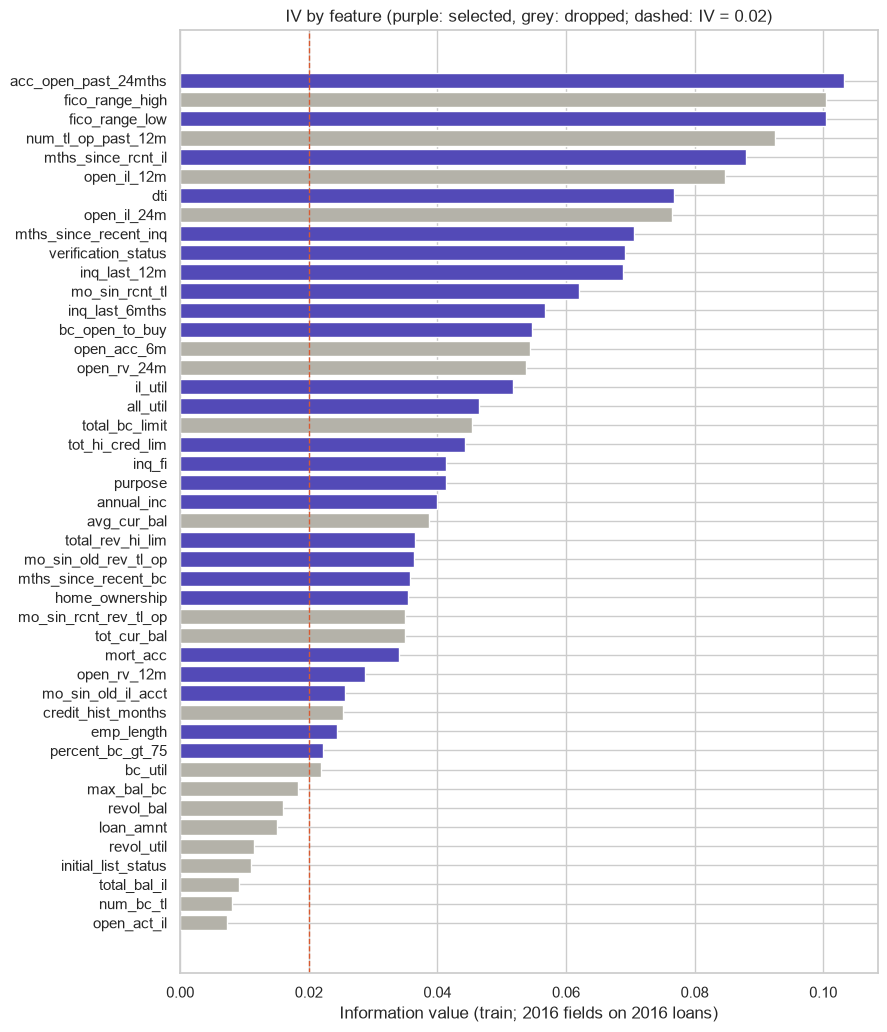

In [10]:
t = table.sort_values("iv", ascending=True)
t = t[t["iv"] >= 0.005]
colors = ["#534AB7" if k == "keep" else "#B4B2A9" for k in t["decision"]]
fig, ax = plt.subplots(figsize=(9, 0.25 * len(t) + 1))
ax.barh(t.index, t["iv"], color=colors)
ax.axvline(MIN_IV, color="#D85A30", ls="--", lw=1)
ax.set_xlabel("Information value (train; 2016 fields on 2016 loans)")
ax.set_title("IV by feature (purple: selected, grey: dropped; dashed: IV = 0.02)")
save(fig, "iv")
plt.show()

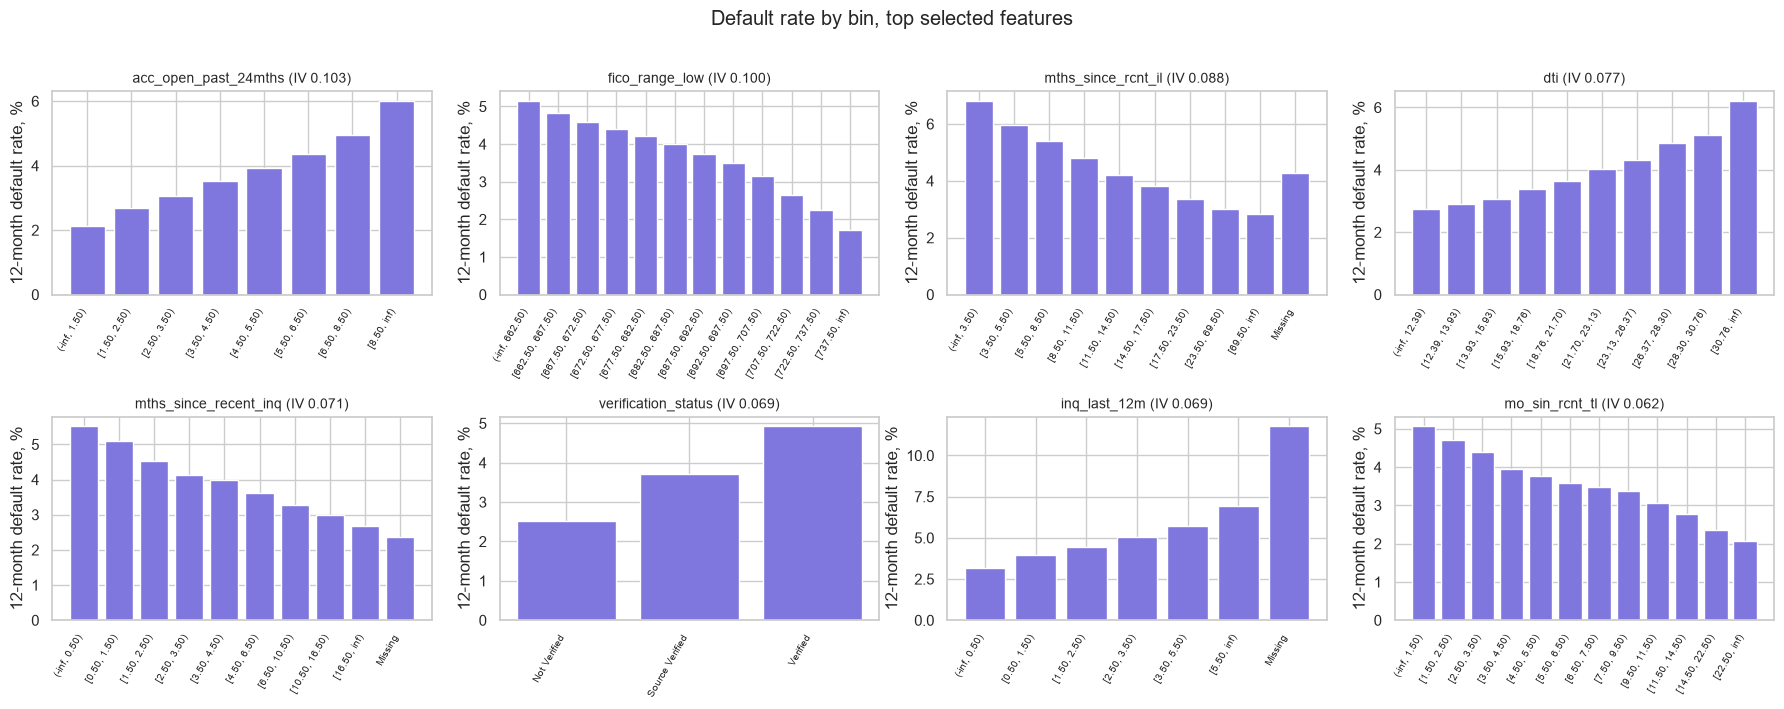

In [11]:
top = SELECTED[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, f in zip(axes.flat, top):
    bt = binning_table(f)
    bt = bt[bt["Count"] > 0]
    labels = list(bt["Bin"])
    ax.bar(range(len(bt)), bt["Event rate"] * 100, color="#7F77DD")
    ax.set_xticks(range(len(bt)))
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
    ax.set_title(f"{f} (IV {table.loc[f, 'iv']:.3f})", fontsize=10)
    ax.set_ylabel("12-month default rate, %")
fig.suptitle("Default rate by bin, top selected features", y=1.01)
fig.tight_layout()
save(fig, "bins_top")
plt.show()

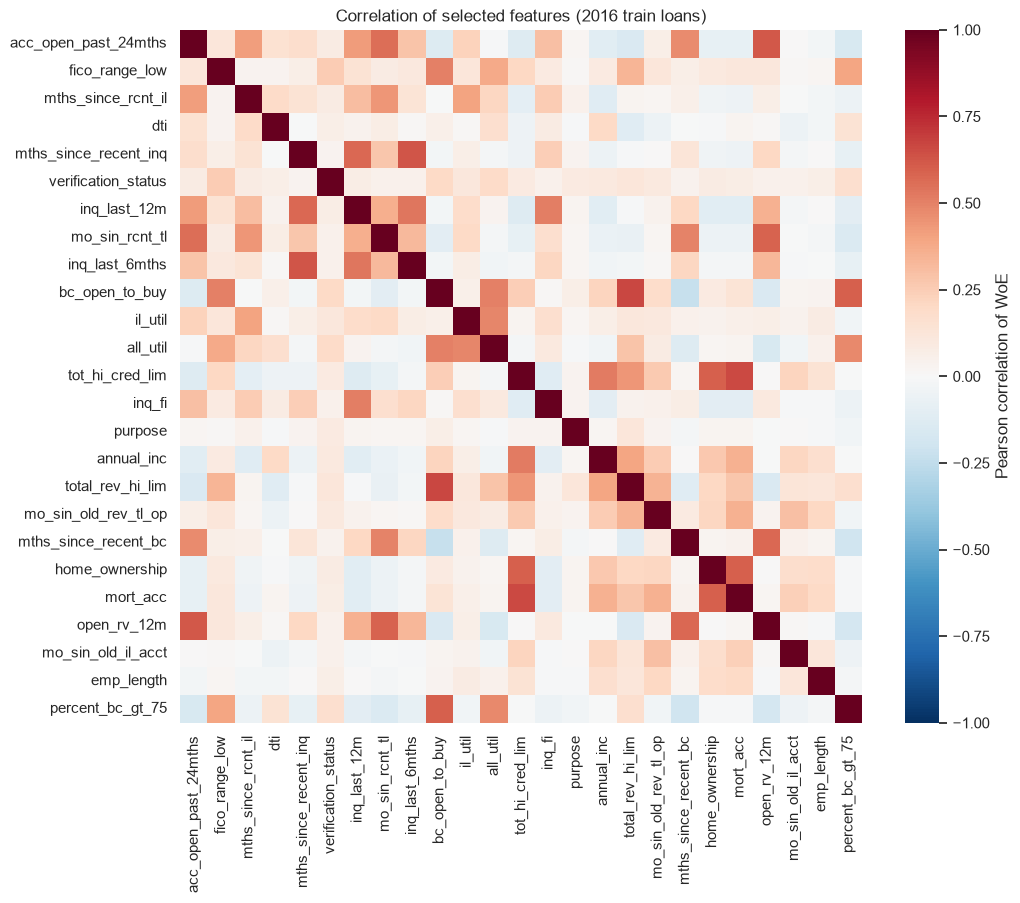

In [12]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(W16[SELECTED].corr(), cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax,
            cbar_kws={"label": "Pearson correlation of WoE"})
ax.set_title("Correlation of selected features (2016 train loans)")
save(fig, "corr_selected")
plt.show()

## 7. Save

* `reports/tables/03_feature_selection.csv`: every candidate with its metrics, decision and
  reason (an audit trail for the validator);
* `reports/tables/03_binning_tables.csv`: bins, counts, default rates and WoE of the
  selected features;
* `models/scorecard_binning.pkl`: the fitted binning, reused by notebook 04 (not in git).

In [13]:
table.index.name = "feature"
table.round(5).to_csv(TABLES / "03_feature_selection.csv")

bt_all = []
for f in SELECTED:
    bt = binning_table(f)[["Bin", "Count", "Count (%)", "Event", "Event rate", "WoE", "IV"]].copy()
    bt.insert(0, "feature", f)
    bt_all.append(bt)
pd.concat(bt_all).round(5).to_csv(TABLES / "03_binning_tables.csv", index=False)

MODELS.mkdir(exist_ok=True)
with open(MODELS / "scorecard_binning.pkl", "wb") as fh:
    pickle.dump({"binning": binning, "selected": SELECTED}, fh)
print("saved:", len(SELECTED), "selected features")
print(SELECTED)

saved: 25 selected features
['acc_open_past_24mths', 'fico_range_low', 'mths_since_rcnt_il', 'dti', 'mths_since_recent_inq', 'verification_status', 'inq_last_12m', 'mo_sin_rcnt_tl', 'inq_last_6mths', 'bc_open_to_buy', 'il_util', 'all_util', 'tot_hi_cred_lim', 'inq_fi', 'purpose', 'annual_inc', 'total_rev_hi_lim', 'mo_sin_old_rev_tl_op', 'mths_since_recent_bc', 'home_ownership', 'mort_acc', 'open_rv_12m', 'mo_sin_old_il_acct', 'emp_length', 'percent_bc_gt_75']


## 8. Conclusions

### Result
**25 of 78 candidate features are selected** for the logistic scorecard.

| Step | Removed |
|---|---|
| Weak (IV < 0.02) | 41 |
| Suspicious (IV > 0.5) | 0 |
| Unstable (PSI > 0.25 or risk order changes) | 0 |
| Correlated (r > 0.7 with a stronger feature) | 12 |
| Multicollinear (VIF > 5) | 0 (max VIF 3.7) |

### What predicts default within 12 months
- **Credit-seeking behaviour** is the strongest signal: accounts opened in the last 24 months
  (IV 0.103), months since the last instalment loan (0.088), recent inquiries (0.07).
  Borrowers who are actively taking on new credit default sooner.
- **FICO** (0.100) and **DTI** (0.077) behave as expected: risk falls with FICO and rises with DTI,
  monotonically across 12 and 10 bins.
- Every feature is individually **weak** on the classic IV scale (max 0.10). The scorecard's
  power has to come from combining them; with the 12-month target, individual signals are
  weaker than with a lifetime target.

### Quality checks
- **No overfitting of the bins:** univariate Gini on test differs from train by at most 0.015.
- **Stable inside train (2013–2014 vs 2016):** PSI of the selected features ≤ 0.061, rank
  correlation of bin default rates ≥ 0.74. The only feature with a large shift,
  `initial_list_status` (PSI 0.41: Lending Club changed its whole/fractional listing policy),
  is weak anyway.
- `fico_range_high` is a copy of `fico_range_low` + 4 (r = 1.00) and is removed as correlated.

### Findings for Part 2 (validation)
- **2016 bureau fields.** 6 selected features (`mths_since_rcnt_il`, `inq_last_12m`, `il_util`,
  `all_util`, `inq_fi`, `open_rv_12m`) are binned on 2016 loans only; for the 61% of train issued
  before 2016 they carry a neutral WoE of 0. In 2017 they are filled for every loan, so their
  effective weight in out-of-time scoring is larger than in training. Check in notebook 05
  that this does not distort calibration.
- **Counter-intuitive sign: `verification_status`.** Verified-income borrowers default more
  (4.9% vs 2.5% for not verified). This is a known Lending Club effect: income is verified
  for riskier applications, so the flag reflects the lender's own risk view. Kept, but it
  must be explained in the model documentation.
- **Delinquency history carries almost no signal** (`delinq_2yrs`, `pub_rec`,
  `mths_since_last_delinq`, `pub_rec_bankruptcies`: IV ≤ 0.003). Lending Club's credit policy
  rejects most applicants with recent delinquencies, so among funded loans these fields barely
  vary. This is a **selection effect**: the model learns only from approved loans and cannot be
  trusted on applicants the policy used to reject (no reject inference).
- `emp_length`: missing is the riskiest category (5.4% default rate), kept as its own bin.